# Graded lab: Implement DQN for LunarLander

**Team:** Jann Erhardt, Gian Gamper (gampegia)

This lab is a modified verstion of a notebookfrom the Deep RL Course on HuggingFace.

In this notebook, you'll train your **Deep Q-Network (DQN) agent** to play an Atari game. Your agent controls a spaceship, the Lunar Lander, to learn how to **land correctly on the Moon**.

*All your answers should be written in this notebook. You shouldn’t need to write or modify any other files. The parts of code that need to be changed as labelled as TODOs in the comments. You should execute every block of code to not miss any dependency.*

### The environment

We will use the [LunarLander-v2](https://gymnasium.farama.org/environments/box2d/lunar_lander/) environment from Gymnasium. This environment is a classic rocket trajectory optimization problem. According to Pontryagin’s maximum principle, it is optimal to fire the engine at full throttle or turn it off. This is the reason why this environment has discrete actions: engine on or off.

In [6]:
%%html
<video controls autoplay><source src="https://huggingface.co/sb3/ppo-LunarLander-v2/resolve/main/replay.mp4" type="video/mp4"></video>

### Note on HuggingFace

You can easily find the HuggingFace original notebook which uses the [Stable-Baselines3](https://stable-baselines3.readthedocs.io/en/master/). This library provides a set of reliable implementations of reinforcement learning algorithms in PyTorch.

The Hugging Face Hub 🤗 works as a central place where anyone can share and explore models and datasets. It has versioning, metrics, visualizations and other features that will allow you to easily collaborate with others.

You can see here all the Deep reinforcement Learning models available here https://huggingface.co/models?pipeline_tag=reinforcement-learning&sort=downloads

## Install dependencies and create a virtual screen 🔽

The first step is to install the dependencies, we’ll install multiple ones.

- `gymnasium[box2d]`: Contains the LunarLander-v2 environment
- `stable-baselines3[extra]`: The deep reinforcement learning library.


In [7]:
# !apt install swig cmake

In [8]:
# !pip install gymnasium[box2d]

In [9]:
# !pip install stable-baselines3==2.0.0a5 pyvirtualdisplay

During the notebook, we'll need to generate a replay video. To do so, with colab, **we need to have a virtual screen to be able to render the environment** (and thus record the frames).

Hence the following cell will install virtual screen libraries and create and run a virtual screen

## Import the packages

In [10]:
import gymnasium as gym

from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.monitor import Monitor

## Create the LunarLander environment and understand how it works

### [The environment](https://gymnasium.farama.org/environments/box2d/lunar_lander/)

The goal is to train our agent, a [Lunar Lander](https://gymnasium.farama.org/environments/box2d/lunar_lander/), **to land correctly on the moon**. To do that, the agent needs to learn **to adapt its speed and position (horizontal, vertical, and angular) to land correctly.**

In [11]:
# We create our environment with gym.make("<name_of_the_environment>")
eval_env = gym.make("LunarLander-v2")
eval_env.reset()
print("_____OBSERVATION SPACE_____ \n")
print("Observation Space Shape", eval_env.observation_space.shape)
print("Sample observation", eval_env.observation_space.sample()) # Get a random observation

_____OBSERVATION SPACE_____ 

Observation Space Shape (8,)
Sample observation [84.024994   46.859474    1.4605995   0.13781627  1.4932475  -1.9044547
  0.19320868  0.6002267 ]


We see with `Observation Space Shape (8,)` that the observation is a vector of size 8, where each value contains different information about the lander:
- Horizontal pad coordinate (x)
- Vertical pad coordinate (y)
- Horizontal speed (x)
- Vertical speed (y)
- Angle
- Angular speed
- If the left leg contact point has touched the land (boolean)
- If the right leg contact point has touched the land (boolean)


In [12]:
print("\n _____ACTION SPACE_____ \n")
print("Action Space Shape", eval_env.action_space.n)
print("Action Space Sample", eval_env.action_space.sample()) # Take a random action


 _____ACTION SPACE_____ 

Action Space Shape 4
Action Space Sample 3


The action space (the set of possible actions the agent can take) is discrete with 4 actions available:

- Action 0: Do nothing,
- Action 1: Fire left orientation engine,
- Action 2: Fire the main engine,
- Action 3: Fire right orientation engine.

Reward function (the function that will gives a reward at each timestep):

After every step a reward is granted. The total reward of an episode is the **sum of the rewards for all the steps within that episode**.

For each step, the reward:

- Is increased/decreased the closer/further the lander is to the landing pad.
-  Is increased/decreased the slower/faster the lander is moving.
- Is decreased the more the lander is tilted (angle not horizontal).
- Is increased by 10 points for each leg that is in contact with the ground.
- Is decreased by 0.03 points each frame a side engine is firing.
- Is decreased by 0.3 points each frame the main engine is firing.

The episode receive an **additional reward of -100 or +100 points for crashing or landing safely respectively.**

An episode is **considered a solution if it scores at least 200 points.**

#### Vectorized Environment

- We create a vectorized environment (a method for stacking multiple independent environments into a single environment) of 16 environments, this way, **we'll have more diverse experiences during the training.**

In [13]:
# Create the environment
eval_env = make_vec_env('LunarLander-v2', n_envs=16)

## Create the Model

Remember the goal: **being able to land the Lunar Lander to the Landing Pad correctly by controlling left, right and main orientation engine**. Based on this, s build the algorithm we're going to use to solve this Problem.

To solve this problem, you're going to implement DQN from scratch.

In [14]:
import itertools
import torch
import torch.nn as nn

def activation_function(name: str) -> nn.Module:
    """Returns the activation function given its name."""
    if name == "relu":
        return nn.ReLU()
    elif name == "tanh":
        return nn.Tanh()
    elif name == "sigmoid":
        return nn.Sigmoid()
    elif name == "gelu":
        return nn.GELU()
    elif name == "none":
        return nn.Identity()
    else:
        raise ValueError(f"Unknown activation function: {name}")

class QNetwork(nn.Module):
    """Maps a batch of states to one Q-value per action."""

    def __init__(self, state_dim: int, n_actions: int, activation: str = "relu", hidden_sizes: tuple[int, ...] = (128, 128)):
        super().__init__()
        layers = [nn.Linear(state_dim, hidden_sizes[0]), activation_function(activation)]
        for in_size, out_size in itertools.pairwise(hidden_sizes):
            layers.append(nn.Linear(in_size, out_size))
            layers.append(activation_function(activation))
        self.net = nn.Sequential(*layers)
        self.out = nn.Linear(hidden_sizes[-1], n_actions)

    def forward(self, states: torch.Tensor) -> torch.Tensor:
        """Returns the Q-values for each action given a batch of states."""
        return self.out(self.net(states))

In [15]:
import numpy as np

class ReplayBuffer:
    """Fixed-size ring buffer of transitions, sampled uniformly at random."""

    def __init__(self, capacity: int, state_dim: int, seed: int | None = None):
        self.capacity = capacity
        self.states = np.zeros((capacity, state_dim), dtype=np.float32)
        self.actions = np.zeros(capacity, dtype=np.int64)
        self.rewards = np.zeros(capacity, dtype=np.float32)
        self.next_states = np.zeros((capacity, state_dim), dtype=np.float32)
        self.dones = np.zeros(capacity, dtype=np.float32)
        self.ptr = 0   # next index to write to
        self.size = 0  # number of filled slots
        self.rng = np.random.default_rng(seed)

    def add(self, states, actions, rewards, next_states, dones) -> None:
        """Store a batch of transitions (one per parallel env), overwriting the oldest when full."""
        n = len(states)
        idx = (self.ptr + np.arange(n)) % self.capacity
        self.states[idx] = states
        self.actions[idx] = actions
        self.rewards[idx] = rewards
        self.next_states[idx] = next_states
        self.dones[idx] = dones
        self.ptr = (self.ptr + n) % self.capacity
        self.size = min(self.size + n, self.capacity)

    def sample(self, batch_size: int):
        """Return a random batch as numpy arrays: (states, actions, rewards, next_states, dones)."""
        if self.size == 0:
            raise ValueError("Cannot sample from an empty replay buffer")
        idx = self.rng.integers(0, self.size, size=batch_size)
        return (
            self.states[idx],
            self.actions[idx],
            self.rewards[idx],
            self.next_states[idx],
            self.dones[idx],
        )

    def __len__(self) -> int:
        return self.size


In [16]:
import numpy as np

class DQNAgent:
    """DQN agent: online + target Q-networks, epsilon-greedy acting, TD learning."""

    def __init__(self, state_dim: int, n_actions: int, device: torch.device,
             hidden_sizes: tuple[int, ...] = (128, 128), activation: str = "relu",
             lr: float = 1e-3, gamma: float = 0.99,
             loss: str = "huber", max_grad_norm: float = 10.0,
             seed: int | None = None):
        if loss not in ["huber", "mse"]:
            raise ValueError(f"Invalid loss function: {loss}")
        self.device = device
        self.gamma = gamma
        self.loss = loss
        self.max_grad_norm = max_grad_norm if max_grad_norm is not None else 10.0
        self.n_actions = n_actions
        self.seed = seed if seed is not None else 42
        torch.manual_seed(self.seed)
        self.model = QNetwork(state_dim, n_actions, hidden_sizes=hidden_sizes, activation=activation).to(device)
        self.target_model = QNetwork(state_dim, n_actions, hidden_sizes=hidden_sizes, activation=activation).to(device)
        self.update_target()
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=lr)
        self.rng = np.random.default_rng(self.seed)

    def select_action(self, states: np.ndarray, epsilon: float = 0.0) -> np.ndarray:
        """Return one action per state, epsilon-greedy w.r.t. the online network."""
        states = torch.as_tensor(states, device=self.device, dtype=torch.float32)
        with torch.no_grad():
            q_values = self.model(states).cpu().numpy()
        for i in range(len(states)):
            if self.rng.random() < epsilon:
                q_values[i] = self.rng.uniform(size=self.n_actions)
        return np.argmax(q_values, axis=1)

    def learn(self, batch) -> float:
        """One gradient step on a sampled batch; returns the loss."""
        states, actions, rewards, next_states, dones = batch
        states = torch.as_tensor(states, device=self.device, dtype=torch.float32)
        actions = torch.as_tensor(actions, device=self.device, dtype=torch.int64)
        rewards = torch.as_tensor(rewards, device=self.device, dtype=torch.float32)
        next_states = torch.as_tensor(next_states, device=self.device, dtype=torch.float32)
        dones = torch.as_tensor(dones, device=self.device, dtype=torch.float32)
        with torch.no_grad():
            target = self.target_model(next_states)
        prediction = self.model(states)
        expected_reward = rewards + self.gamma * (1 - dones) * torch.max(target, dim=1).values
        if self.loss == "huber":
            loss = nn.functional.smooth_l1_loss(prediction[torch.arange(len(actions), device=self.device), actions], expected_reward)
        elif self.loss == "mse":
            loss = nn.functional.mse_loss(prediction[torch.arange(len(actions), device=self.device), actions], expected_reward)
        else:
            raise ValueError(f"Invalid loss function: {self.loss}")
        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.model.parameters(), self.max_grad_norm)
        self.optimizer.step()
        return loss.item()


    def update_target(self) -> None:
        """Copy the online network's weights into the target network."""
        self.target_model.load_state_dict(self.model.state_dict())

## Train the DQN agent
- Let's train our agent for 1,000,000 timesteps, don't forget to use GPU (on your local installation, Google Colab or similar). You will notice that experiments will take considerably longer than previous labs.

#### Solution

### Hyperparameters
All step counts are in **transitions** (one `env.step` on the 16-env VecEnv = 16 transitions), matching SB3's `total_timesteps` convention.


In [17]:
# --- Training budget ---
N_ENVS = 16                      # parallel envs from make_vec_env; more diverse experience per env.step
TOTAL_TIMESTEPS = 1_000_000      # transitions, as required by the lab (= 62,500 env.step calls)

# --- Replay buffer ---
BUFFER_SIZE = 100_000            # ~10% of all training data: large enough to decorrelate batches and keep old situations, small enough that stale early-policy data gets replaced
BATCH_SIZE = 128                 # tuned RL-Zoo value for LunarLander; larger batches give less noisy gradient estimates
LEARNING_STARTS = 10_000         # fill the buffer with ~10k random transitions first so the first updates see diverse data

# --- Update schedule ---
TRAIN_FREQ = 1                   # env.step calls between learning phases: learn after every vectorised step
GRADIENT_STEPS = 4               # gradient steps per learning phase -> 4 per 16 transitions = SB3's default replay ratio of 1:4
TARGET_UPDATE_INTERVAL = 1_000   # transitions between target syncs (= 250 gradient steps), close to the tuned RL-Zoo value of 250

# --- Exploration (linear epsilon decay) ---
EPS_START = 1.0                  # the untrained network's greedy actions are meaningless, so start fully random
EPS_END = 0.05                   # keep a little exploration for the rest of training (SB3 default)
EPS_DECAY_FRACTION = 0.1         # reach EPS_END after the first 10% of training (RL-Zoo uses 12%)

# --- Agent ---
HIDDEN_SIZES = (256, 256)        # tuned RL-Zoo architecture; plenty of capacity for an 8-dim state
ACTIVATION = "relu"              # standard for DQN on low-dimensional states
LR = 6.3e-4                      # tuned RL-Zoo learning rate for LunarLander with Adam
GAMMA = 0.99                     # long horizon: the +100 landing bonus arrives only at the end of a long episode
LOSS = "huber"                   # less sensitive than MSE to the large TD errors from +-100 crash/landing rewards
MAX_GRAD_NORM = 10.0             # SB3 default; safety net against occasional exploding updates
SEED = 42                        # reproducible network init, exploration and buffer sampling

DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")


In [18]:
def linear_epsilon(current_step: int) -> float:
    """Linearly decay epsilon from start to end over the first decay_fraction of total_steps."""
    decay_steps = int(TOTAL_TIMESTEPS * EPS_DECAY_FRACTION)
    if current_step >= decay_steps:
        return EPS_END
    else:
        return EPS_START + (EPS_END - EPS_START) * (current_step / decay_steps)

In [19]:
agent = DQNAgent(
    state_dim=eval_env.observation_space.shape[0],
    n_actions=eval_env.action_space.n,
    device=DEVICE,
    hidden_sizes=HIDDEN_SIZES,
    activation=ACTIVATION,
    lr=LR,
    gamma=GAMMA,
    loss=LOSS,
    max_grad_norm=MAX_GRAD_NORM,
    seed=SEED
)
replay_buffer = ReplayBuffer(
    capacity=BUFFER_SIZE,
    state_dim=eval_env.observation_space.shape[0],
    seed=SEED
)

eval_episode_rewards = []
episode_end_steps = []
losses = []

eval_states = eval_env.reset()
transitions = 0
last_target_update = 0

while transitions < TOTAL_TIMESTEPS:
    # Act
    epsilon = linear_epsilon(transitions)
    actions = agent.select_action(eval_states, epsilon)

    # Step
    next_states, rewards, dones, infos = eval_env.step(actions)
    transitions += N_ENVS

    # Repair s' for terminated or truncated episodes
    real_next_states = next_states.copy()
    for i in range(len(dones)):
        if dones[i]:
            real_next_states[i] = infos[i]["terminal_observation"]

    # Store transitions in the replay buffer
    replay_buffer.add(eval_states, actions, rewards, real_next_states, dones)

    # Log finished episodes
    for info in infos:
        if "episode" in info.keys():
            eval_episode_rewards.append(info["episode"]["r"])
            episode_end_steps.append(transitions)

    # Learn
    if transitions >= LEARNING_STARTS and transitions % TRAIN_FREQ == 0:
        for _ in range(GRADIENT_STEPS):
            batch = replay_buffer.sample(BATCH_SIZE)
            loss = agent.learn(batch)
            losses.append(loss)

    # Sync network
    if transitions - last_target_update >= TARGET_UPDATE_INTERVAL:
        agent.update_target()
        last_target_update = transitions

    # Progress report
    if transitions % 1_000 == 0:
        mean_reward = np.mean(eval_episode_rewards[-100:]) if eval_episode_rewards else float("nan")
        print(f"Step {transitions}: mean reward (last 100 episodes) = {mean_reward:.2f}, epsilon = {epsilon:.3f}")

    # move on
    eval_states = next_states

Step 2000: mean reward (last 100 episodes) = -189.42, epsilon = 0.981
Step 4000: mean reward (last 100 episodes) = -192.89, epsilon = 0.962
Step 6000: mean reward (last 100 episodes) = -182.04, epsilon = 0.943
Step 8000: mean reward (last 100 episodes) = -169.94, epsilon = 0.924
Step 10000: mean reward (last 100 episodes) = -174.52, epsilon = 0.905
Step 12000: mean reward (last 100 episodes) = -173.74, epsilon = 0.886


KeyboardInterrupt: 

In [20]:
import json
from datetime import datetime
from pathlib import Path

RUNS_DIR = Path("runs")

def save_training_results(model_type: str, agent, config: dict, losses, episode_rewards, episode_end_steps) -> Path:
    """Save the trained model, its config and training curves into a new run folder."""
    run_name = f"{model_type}_lunarlander_{datetime.now().strftime('%Y%m%d-%H%M%S')}"
    run_dir = RUNS_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=False)
    torch.save(agent.model.state_dict(), run_dir / "model.pt")
    (run_dir / "config.json").write_text(json.dumps(config, indent=2))
    np.save(run_dir / "losses.npy", np.asarray(losses))
    np.save(run_dir / "episode_rewards.npy", np.asarray(episode_rewards))
    np.save(run_dir / "episode_end_steps.npy", np.asarray(episode_end_steps))
    print(f"Saved run to {run_dir}")
    return run_dir


def load_run(run_dir: str | Path, device: torch.device = DEVICE) -> tuple[DQNAgent, dict, dict[str, np.ndarray]]:
    """Rebuild a trained agent from a run folder; returns (agent, config, training curves)."""
    run_dir = Path(run_dir)
    if not run_dir.is_dir():
        raise FileNotFoundError(f"Run folder not found: {run_dir}")
    config = json.loads((run_dir / "config.json").read_text())
    agent = DQNAgent(
        state_dim=config["state_dim"],
        n_actions=config["n_actions"],
        device=device,
        hidden_sizes=tuple(config["hidden_sizes"]),
        activation=config["activation"],
        lr=config["lr"],
        gamma=config["gamma"],
        loss=config["loss"],
        max_grad_norm=config["max_grad_norm"],
        seed=config["seed"],
    )
    agent.model.load_state_dict(torch.load(run_dir / "model.pt", map_location=device))
    agent.update_target()
    curves = {
        name: np.load(run_dir / f"{name}.npy")
        for name in ("losses", "episode_rewards", "episode_end_steps")
    }
    return agent, config, curves


In [21]:
config = {
    "state_dim": eval_env.observation_space.shape[0],
    "n_actions": int(eval_env.action_space.n),
    "n_envs": N_ENVS,
    "total_timesteps": TOTAL_TIMESTEPS,
    "buffer_size": BUFFER_SIZE,
    "batch_size": BATCH_SIZE,
    "learning_starts": LEARNING_STARTS,
    "train_freq": TRAIN_FREQ,
    "gradient_steps": GRADIENT_STEPS,
    "target_update_interval": TARGET_UPDATE_INTERVAL,
    "eps_start": EPS_START,
    "eps_end": EPS_END,
    "eps_decay_fraction": EPS_DECAY_FRACTION,
    "hidden_sizes": list(HIDDEN_SIZES),
    "activation": ACTIVATION,
    "lr": LR,
    "gamma": GAMMA,
    "loss": LOSS,
    "max_grad_norm": MAX_GRAD_NORM,
    "seed": SEED,
    "device": str(DEVICE),
}
run_dir = save_training_results("dqn", agent, config, losses, eval_episode_rewards, episode_end_steps)


Saved run to runs/dqn_lunarlander_20261125-093649


## Evaluate the agent
- Now that our Lunar Lander agent is trained, we need to **check its performance**.

**Note**: When you evaluate your agent, you should not use your training environment but create an evaluation environment.

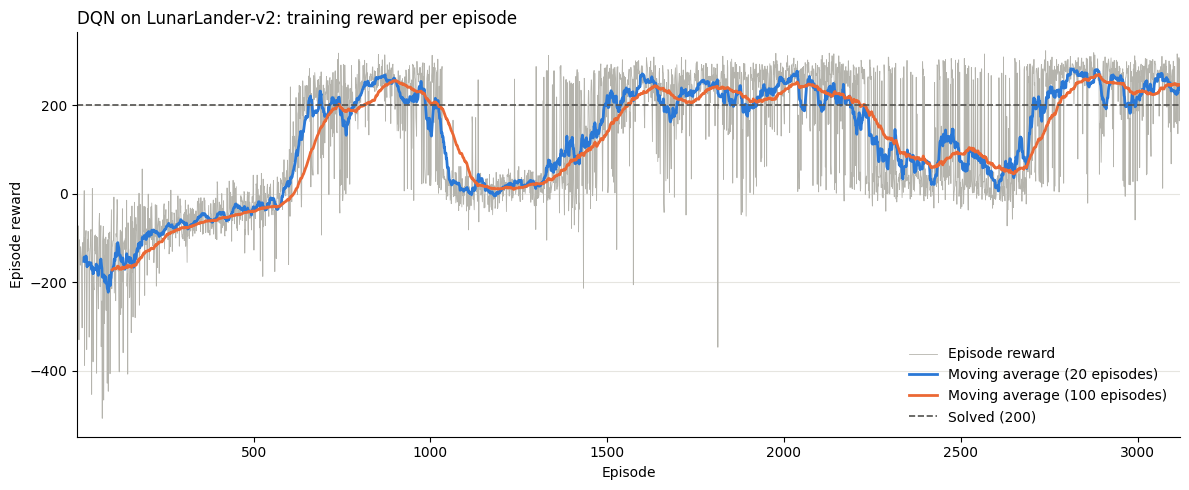

In [22]:
import matplotlib.pyplot as plt

RUN_DIR = Path("runs/dqn_lunarlander_20261125-085950")
agent, config, curves = load_run(RUN_DIR)

SOLVED_THRESHOLD = 200
SMOOTHING_WINDOWS = {20: "#2a78d6", 100: "#eb6834"}  # window size -> line colour
RAW_COLOR = "#b5b4ad"
TEXT_SECONDARY = "#52514e"


def moving_average(values: np.ndarray, window: int) -> np.ndarray:
    """Mean over each full window of `window` consecutive values (length: len(values) - window + 1)."""
    return np.convolve(values, np.ones(window) / window, mode="valid")


def plot_learning_curve(curves: dict[str, np.ndarray], run_dir: Path) -> None:
    """Plot episode rewards with moving averages over episodes and save it into the run folder."""
    rewards = curves["episode_rewards"]
    episodes = np.arange(1, len(rewards) + 1)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(episodes, rewards, color=RAW_COLOR, linewidth=0.6, label="Episode reward")
    for window, color in SMOOTHING_WINDOWS.items():
        # each average belongs to the last episode of its window
        ax.plot(episodes[window - 1:], moving_average(rewards, window),
                color=color, linewidth=2, label=f"Moving average ({window} episodes)")
    ax.axhline(SOLVED_THRESHOLD, color=TEXT_SECONDARY, linestyle="--", linewidth=1.2,
               label=f"Solved ({SOLVED_THRESHOLD})")

    ax.set_title("DQN on LunarLander-v2: training reward per episode", loc="left")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Episode reward")
    ax.set_xlim(1, len(rewards))
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower right", frameon=False)

    fig.tight_layout()
    fig.savefig(run_dir / "learning_curve.png", dpi=200)  # save before show, or the file is blank
    plt.show()


plot_learning_curve(curves, RUN_DIR)


In [23]:
# Evaluate the agent
EVAL_EPISODES = 10
EVAL_SEED = 123  # different from training, so the agent is tested on unseen start conditions


def run_eval_episodes(agent: DQNAgent, n_episodes: int = EVAL_EPISODES, seed: int = EVAL_SEED) -> np.ndarray:
    """Play n_episodes greedily (epsilon = 0) on a fresh environment; returns the episode rewards."""
    eval_env = make_vec_env("LunarLander-v2", n_envs=1, seed=seed)
    eval_states = eval_env.reset()
    eval_episode_rewards = []
    while len(eval_episode_rewards) < n_episodes:
        actions = agent.select_action(eval_states, epsilon=0.0)
        eval_states, rewards, dones, infos = eval_env.step(actions)
        for i in range(len(dones)):
            if dones[i]:
                eval_episode_rewards.append(infos[i]["episode"]["r"])
    eval_env.close()
    return np.asarray(eval_episode_rewards)


def save_eval_rewards(run_dir: str | Path, eval_rewards: np.ndarray) -> Path:
    """Store the raw evaluation rewards in the run folder (overwrites a previous evaluation)."""
    path = Path(run_dir) / "eval_rewards.npy"
    np.save(path, eval_rewards)
    return path


def evaluate_run(run_dir: str | Path, n_episodes: int = EVAL_EPISODES, seed: int = EVAL_SEED) -> np.ndarray:
    """Load a run, evaluate it greedily, print mean +/- std and save the raw rewards into the run folder."""
    eval_agent, _, _ = load_run(run_dir)
    eval_rewards = run_eval_episodes(eval_agent, n_episodes, seed)
    path = save_eval_rewards(run_dir, eval_rewards)
    print(f"{Path(run_dir).name}: {eval_rewards.mean():.2f} +/- {eval_rewards.std():.2f} "
          f"over {n_episodes} episodes (seed {seed}) -> {path}")
    return eval_rewards


eval_episode_rewards = evaluate_run(RUN_DIR)
mean_reward, std_reward = np.mean(eval_episode_rewards), np.std(eval_episode_rewards)

# Print the results
print(f"{mean_reward:.2f} +/- {std_reward:.2f}")


dqn_lunarlander_20261125-085950: 273.54 +/- 24.55 over 10 episodes (seed 123) -> runs/dqn_lunarlander_20261125-085950/eval_rewards.npy
273.54 +/- 24.55


## Record a video of the agent playing the game

In [24]:
from gymnasium.wrappers import RecordVideo

VIDEO_SEED = 7  # any seed; pick one whose episode you want to show

video_env = RecordVideo(
    gym.make("LunarLander-v2", render_mode="rgb_array"),   # rgb_array = render frames off-screen
    video_folder=str(RUN_DIR / "video"),                    # mp4 ends up inside the run folder
    episode_trigger=lambda episode_id: True,                # record every episode (we only play one)
    name_prefix="dqn_lunarlander",
)

done = False
total_reward = 0.0
video_state, video_info = video_env.reset(seed=VIDEO_SEED)

while not done:
    # select_action expects a batch (N, 8): add a batch axis, then take the single action back out
    action = agent.select_action(video_state[None], epsilon=0.0)[0]
    video_state, reward, done, truncated, info = video_env.step(action)
    total_reward += float(reward)
    if truncated:
        break
video_env.close()
print(f"Video recorded in {video_env.video_recorder.path} with total reward {total_reward:.2f}")

/Users/schiba/Projects/zhaw-bachelor/venv/lib/python3.12/site-packages/gymnasium/wrappers/record_video.py:87: UserWarning: WARN: Overwriting existing videos at /Users/schiba/Projects/zhaw-bachelor/semester-7/rl/Graded_Lab_02/runs/dqn_lunarlander_20261125-085950/video folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Moviepy - Building video /Users/schiba/Projects/zhaw-bachelor/semester-7/rl/Graded_Lab_02/runs/dqn_lunarlander_20261125-085950/video/dqn_lunarlander-episode-0.mp4.
Moviepy - Writing video /Users/schiba/Projects/zhaw-bachelor/semester-7/rl/Graded_Lab_02/runs/dqn_lunarlander_20261125-085950/video/dqn_lunarlander-episode-0.mp4



Moviepy - Done !
Moviepy - video ready /Users/schiba/Projects/zhaw-bachelor/semester-7/rl/Graded_Lab_02/runs/dqn_lunarlander_20261125-085950/video/dqn_lunarlander-episode-0.mp4
Video recorded in /Users/schiba/Projects/zhaw-bachelor/semester-7/rl/Graded_Lab_02/runs/dqn_lunarlander_20261125-085950/video/dqn_lunarlander-episode-0.mp4 with total reward 263.62
